# 02 Baselines on the validation year

- What it does: checks the evaluation code, then scores three baselines on 2023: random order (B0), past failure rate (B1) and logistic regression (B2).
- Inputs: `data/processed/model_table.parquet`.
- Outputs: `preds/B0_random_val.csv`, `preds/B1_past_fail_rate_val.csv`, `preds/B2_logreg_val.csv`, `results/validation_baselines.csv`, `results/figures/gains_curve_val_baselines.png`.

The test years (2024 onward) are not used anywhere in this notebook.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import evaluate as E
from src import models as M

SEED = 42
np.random.seed(SEED)

## 1. Check the metrics

Capacity is fixed: ISD visits the riskiest 20% of inspections first.

- Hit rate (`precision_at_k`): the share of those visits that find a failure. This is the headline metric.
- `catch_at_k`: the share of all failures that those visits find.

The self-test confirms that a perfect score gives `catch_at_k = min(1, k / base rate)` and a random score gives about `k`.

In [2]:
E.self_test()

evaluate.py self-test passed: perfect score gives catch_at_k = min(1, k / base rate); random and constant scores give about k


## 2. Load the data

Train on 2016 to 2022, evaluate on 2023.

In [3]:
table = M.load_model_table("../data/processed/model_table.parquet")
train = table[table["split"] == "train"]
val = table[table["split"] == "val"]
y_val = val[M.TARGET].to_numpy()

train_base_rate = train[M.TARGET].mean()
print(f"train: {len(train):,} inspections, fail rate {train_base_rate:.1%}")
print(f"val:   {len(val):,} inspections, fail rate {y_val.mean():.1%}")
print(f"best possible catch_at_k on validation: {min(1, E.K / y_val.mean()):.1%}")

train: 35,915 inspections, fail rate 59.9%
val:   5,520 inspections, fail rate 55.8%
best possible catch_at_k on validation: 35.9%


## 3. Score the baselines

- B0, random order: the routine schedule ignores risk, so this stands for today's process.
- B1, past failure rate: a rule an inspector could apply by hand. First inspections get the train base rate.
- B2, logistic regression on the history features: the predictive baseline.

In [4]:
logreg = M.fit_logreg(train)

val_scores = {
    "B0_random": M.score_random(val),
    "B1_past_fail_rate": M.score_past_fail_rate(val, fallback=train_base_rate),
    "B2_logreg": logreg.predict_proba(M.linear_matrix(val))[:, 1],
}
for name, score in val_scores.items():
    M.save_preds(val, score, f"../preds/{name}_val.csv")

In [5]:
baselines = E.results_table(y_val, val_scores)
baselines.to_csv("../results/validation_baselines.csv", index=False)
baselines.round(3)

,model,auc,catch_at_k,precision_at_k,n,auc_lo,auc_hi,catch_at_k_lo,catch_at_k_hi,precision_at_k_lo,precision_at_k_hi
0,B0_random,0.507,0.206,0.575,5520,0.492,0.523,0.197,0.215,0.546,0.603
1,B1_past_fail_rate,0.685,0.250,0.698,5520,0.672,0.699,0.240,0.260,0.667,0.726
2,B2_logreg,0.761,0.309,0.861,5520,0.748,0.773,0.301,0.318,0.841,0.880


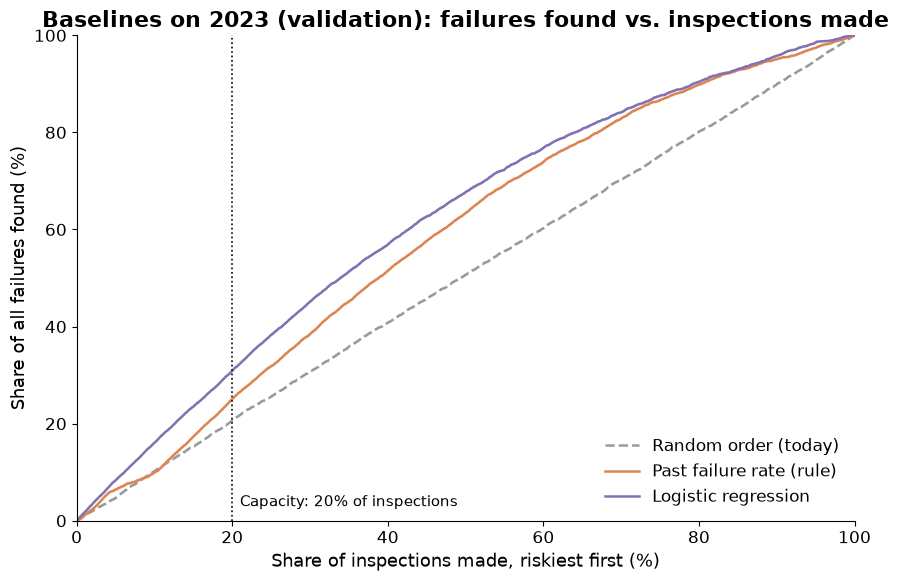

In [6]:
fig = E.plot_gains(y_val, val_scores, "Baselines on 2023 (validation): failures found vs. inspections made",
                   path="../results/figures/gains_curve_val_baselines.png")
plt.show()